# Librerie utili

In [12]:
import os
import pandas as pd
import cv2
from sklearn.model_selection import train_test_split
import torch
from torchvision import transforms
from PIL import Image
import numpy as np
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
import albumentations as A
from albumentations.pytorch import ToTensorV2
import tifffile as tiff
from torchvision.models import resnet18, ResNet18_Weights

# Segmentazione binaria + classificazione

## Operazioni preliminari

### Normalization, equalization, Gaussian filter, mean filter

In [ ]:
#Creazione di immagini modificate
images_base_path = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_images_and_annotations'
for patient in os.listdir(images_base_path):
    patient_folder = os.path.join(images_base_path,patient)
    for image in os.listdir(patient_folder):
        if image.endswith('.tif'):
            image_path = os.path.join(patient_folder,image)
            img = cv2.imread(image_path)
            norm_img = cv2.normalize(img, None, alpha = 0, beta = 255, norm_type = cv2.NORM_MINMAX, dtype = cv2.CV_8UC1)
            img_yuv = cv2.cvtColor(norm_img, cv2.COLOR_BGR2YUV)
            img_yuv[:,:,0] = cv2.equalizeHist(img_yuv[:,:,0])
            img_eq = cv2.cvtColor(img_yuv, cv2.COLOR_YUV2BGR)
            img_gauss = cv2.GaussianBlur(img_eq,(3,3),0)
            img_denoised = cv2.fastNlMeansDenoising(img_gauss,None,10,10)
            eq_img_path = os.path.join(patient_folder,os.path.splitext(image)[0]+'_modified.tif')
            cv2.imwrite(eq_img_path, img_denoised)

### Overlay binario maschere

In [ ]:
masks_base_folder = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\MoNuSAC_masks'
images_base_folder = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\MoNuSAC_images_and_annotations'
for patient in os.listdir(images_base_folder):
    masks_folder = os.path.join(masks_base_folder,patient)
    images_folder = os.path.join(images_base_folder,patient)
    for image_file in os.listdir(images_folder):
        if image_file.endswith('modified.tif'):
            continue
        if image_file.endswith('.tif'):
            msk_folder = os.path.join(masks_folder,os.path.splitext(image_file)[0])
            img = tiff.imread(os.path.join(images_folder,image_file))
            overlay = np.zeros(img.shape[0:2], dtype=np.uint8)
            for layer in os.listdir(msk_folder):
                msk_layer = os.path.join(msk_folder,layer)
                for msk in os.listdir(msk_layer):
                    if msk.endswith('.tif'):
                        msk_file = tiff.imread(os.path.join(msk_layer,msk))
                        n_msk_file = (msk_file > 0).astype(np.uint8)
                        overlay[(n_msk_file == 1) | (overlay == 1)] = [255]
            Image.fromarray(overlay).save(msk_folder+'_binary.tif')

## Segmentazione binaria

### Creazione dataframe

In [ ]:
images_base_path = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_images_and_annotations'
masks_base_path = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_masks'

image_paths = []
mask_paths = []
classes=[]

for name in os.listdir(images_base_path):
    image_folder = os.path.join(images_base_path, name)
    mask_folder = os.path.join(masks_base_path, name)
    if os.path.isdir(image_folder) and os.path.isdir(mask_folder):
        for image_file in os.listdir(image_folder):
            if image_file.endswith('modified.tif'):
                img_path = os.path.join(image_folder, image_file)
                tmp = image_file.replace("_modified.tif", "_binary.tif")
                msk_path = os.path.join(mask_folder,tmp)
                if os.path.exists(img_path) & os.path.exists(msk_path):
                    image_paths.append(img_path)
                    mask_paths.append(msk_path)
                    classes.append('.')
                else:
                    print(f"Mask not found for image: {img_path}")

# Create the pandas DataFrame
df = pd.DataFrame({"image_path": image_paths, "mask_path": mask_paths, "class": classes})

print(f"DataFrame created with {len(df)} entries.")
print(df.head())

DataFrame created with 209 entries.
                                          image_path  \
0  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...   
1  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...   
2  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...   
3  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...   
4  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...   

                                           mask_path class  
0  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...     .  
1  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...     .  
2  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...     .  
3  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...     .  
4  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...     .  


### Controllo casuale

c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedical\MoNuSAC_images_and_annotations\TCGA-MP-A4SY-01Z-00-DX1\TCGA-MP-A4SY-01Z-00-DX1_1_modified.tif
c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedical\MoNuSAC_masks\TCGA-MP-A4SY-01Z-00-DX1\TCGA-MP-A4SY-01Z-00-DX1_1.tif


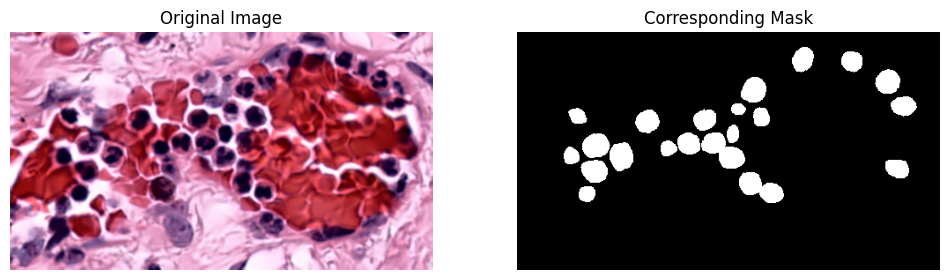

In [ ]:
random_idx = np.random.randint(0, len(df))
random_image_path = df.loc[random_idx, 'image_path']
random_mask_path = df.loc[random_idx, 'mask_path']
print(random_image_path)
print(random_mask_path)

image = tiff.imread(random_image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
mask = tiff.imread(random_mask_path)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap='gray')
plt.title('Corresponding Mask')
plt.axis('off')

plt.show()

### Trasformazioni al dataframe

In [ ]:
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 256

train_transforms = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=45, interpolation=cv2.INTER_LINEAR, border_mode=cv2.BORDER_REFLECT_101, p=0.5),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    ToTensorV2(),
])


### Caricamento Dataset

In [ ]:
class GlandsDataset(torch.utils.data.Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'image_path']
        mask_path = self.df.loc[idx, 'mask_path']

        image = tiff.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = image.astype(np.float32) / 255.0 # normalize

        mask = tiff.imread(mask_path)

        mask[mask > 0] = 1

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        if len(mask.shape) == 2:
            mask = mask.unsqueeze(0)

        return image, mask.float() # for loss function



### Suddivisione del dataframe

In [ ]:
train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['class'],
    random_state=42 # For reproducibility
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Training DataFrame shape: {train_df.shape}")
print(f"Validation DataFrame shape: {val_df.shape}")

Training DataFrame shape: (167, 3)
Validation DataFrame shape: (42, 3)


In [ ]:
BATCH_SIZE = 8

train_dataset = GlandsDataset(train_df, transform=train_transforms)
val_dataset = GlandsDataset(val_df, transform=val_transforms)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Training dataloader batches: {len(train_loader)}")
print(f"Validation dataloader batches: {len(val_loader)}")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Training dataset size: 167
Validation dataset size: 42
Training dataloader batches: 21
Validation dataloader batches: 6
Using device: cpu


### Controllo casuale

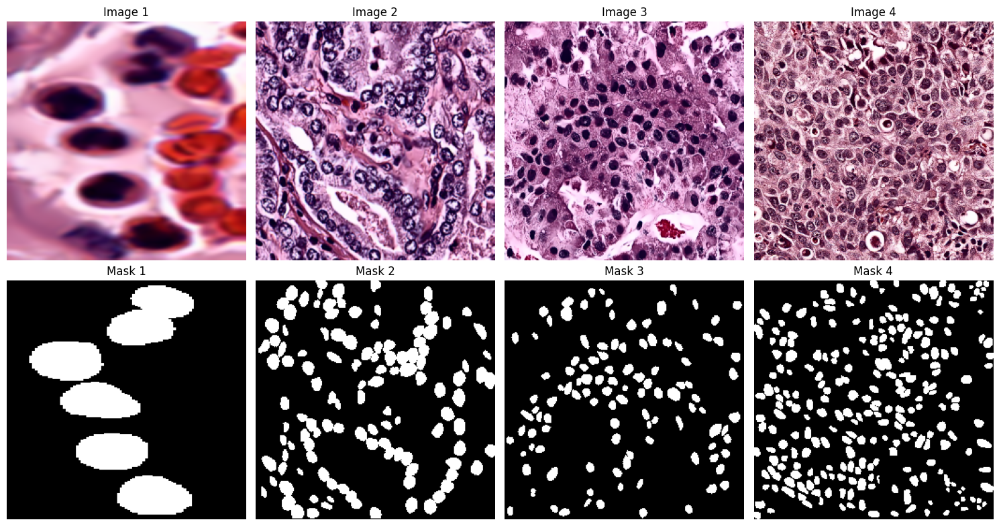

In [ ]:
images, masks = next(iter(train_loader))
images = images.cpu()
maps = masks.cpu()
display_images = images

num_samples_to_show = min(4, BATCH_SIZE)

plt.figure(figsize=(15, 8))
for i in range(num_samples_to_show):
    # Original Image
    plt.subplot(2, num_samples_to_show, i + 1)
    img = display_images[i]
    img = (img - img.min())/(img.max()-img.min())
    plt.imshow(display_images[i].permute(1, 2, 0))
    plt.title(f'Image {i+1}')
    plt.axis('off')

    # Corresponding Mask
    plt.subplot(2, num_samples_to_show, i + 1 + num_samples_to_show)
    plt.imshow(maps[i].squeeze(0), cmap='gray') # Squeeze channel dimension for grayscale mask
    plt.title(f'Mask {i+1}')
    plt.axis('off')

plt.tight_layout()
plt.show()

### Implementazione della rete neurale

In [ ]:
def conv_bn_leru(in_channels, out_channels, kernel_size=3, stride=1, padding=1):
  """
  Implements the sequence of: convolution, batch normalization, and relu activation function (x2)
  """

  return nn.Sequential(
          nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding),
          nn.BatchNorm2d(out_channels),
          nn.ReLU(inplace=True),
          nn.Conv2d(out_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding),
          nn.BatchNorm2d(out_channels),
          nn.ReLU(inplace=True),
  )


def down_pooling():
  """
  Max pooling operation, with a kernel size of 2x2 and a stride of 2
  """
  return nn.MaxPool2d(2, stride = 2)


def up_pooling(in_channels, out_channels, kernel_size=2, stride=2):
    """
    Perform the up scaling operation
    """
    return nn.Sequential(
        nn.ConvTranspose2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )


class UNet(nn.Module):
    """U-Net architecture"""

    def __init__(self, input_channels, nclasses):
        super().__init__()

        self.nclasses = nclasses
        # Encoding layers
        self.conv1 = conv_bn_leru(input_channels,16)
        self.conv2 = conv_bn_leru(16, 32)
        self.conv3 = conv_bn_leru(32, 64)
        self.conv4 = conv_bn_leru(64, 128)
        self.conv5 = conv_bn_leru(128, 256)
        self.down_pooling = down_pooling()

        # Decoding layers
        self.up_pool6 = up_pooling(256, 128)
        self.conv6 = conv_bn_leru(256, 128)
        self.up_pool7 = up_pooling(128, 64)
        self.conv7 = conv_bn_leru(128, 64)
        self.up_pool8 = up_pooling(64, 32)
        self.conv8 = conv_bn_leru(64, 32)
        self.up_pool9 = up_pooling(32, 16)
        self.conv9 = conv_bn_leru(32, 16)

        self.conv10 = nn.Conv2d(16, self.nclasses, 1)
        self.softmax = nn.Softmax(dim=1)


    def forward(self, x):
        # --- Encoder ---
        x1 = self.conv1(x)
        p1 = self.down_pooling(x1)
        x2 = self.conv2(p1)
        p2 = self.down_pooling(x2)
        x3 = self.conv3(p2)
        p3 = self.down_pooling(x3)
        x4 = self.conv4(p3)
        p4 = self.down_pooling(x4)
        x5 = self.conv5(p4)

        # --- Decoder ---
        p6 = self.up_pool6(x5)
        x6 = torch.cat([p6, x4], dim=1)
        x6 = self.conv6(x6)

        p7 = self.up_pool7(x6)
        x7 = torch.cat([p7, x3], dim=1)
        x7 = self.conv7(x7)

        p8 = self.up_pool8(x7)
        x8 = torch.cat([p8, x2], dim=1)
        x8 = self.conv8(x8)

        p9 = self.up_pool9(x8)
        x9 = torch.cat([p9, x1], dim=1)
        x9 = self.conv9(x9)

        output = self.conv10(x9)

        return output


In [ ]:
print("Checking batch shapes:")

# Get a batch from the train dataloader
for images, masks in train_loader:
    print(f"Train Dataloader - Images shape: {images.shape}")
    print(f"Train Dataloader - Masks shape: {masks.shape}")
    break

# Get a batch from the val dataloader
for images, masks in val_loader:
    print(f"Validation Dataloader - Images shape: {images.shape}")
    print(f"Validation Dataloader - Masks shape: {masks.shape}")
    break

Checking batch shapes:
Train Dataloader - Images shape: torch.Size([8, 3, 256, 256])
Train Dataloader - Masks shape: torch.Size([8, 1, 256, 256])
Validation Dataloader - Images shape: torch.Size([8, 3, 256, 256])
Validation Dataloader - Masks shape: torch.Size([8, 1, 256, 256])


In [ ]:
def dice_score(pred, target):
    smooth = 1e-6
    intersection = torch.sum(pred * target)
    return (2. * intersection + smooth) / (torch.sum(pred) + torch.sum(target) + smooth)

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    all_labels_flat = []
    all_preds_flat = []
    dice_total = 0.0
    num_samples = 0

    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)

        # loss computation
        loss = criterion(outputs, labels)

        # Backward pass and update weights
        loss.backward()
        optimizer.step()

        # Update statistics
        running_loss += loss.item() * inputs.size(0)

        # Sigmoid and threshold to get binary prediction
        outputs = torch.sigmoid(outputs)
        preds = (outputs > 0.5).float()

        for i in range(inputs.size(0)):
            dice_total += dice_score(preds[i], labels[i])

        # Collect all labels and predictions and flatten them for F1 score computation
        all_labels_flat.extend(labels.cpu().numpy().ravel())
        all_preds_flat.extend(preds.cpu().numpy().ravel())

        num_samples += inputs.size(0)

    epoch_loss = running_loss / num_samples
    epoch_dice = dice_total / num_samples
    all_labels_flat = np.array(all_labels_flat)
    all_preds_flat = np.array(all_preds_flat)
    f1 = f1_score(all_labels_flat > 0, all_preds_flat > 0, average='binary')

    return epoch_loss, f1, epoch_dice

def validate_one_epoch(model, dataloader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_labels_flat = []
    all_preds_flat = []
    dice_total = 0.0
    num_samples = 0

    # disable gradients
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)

            # Forward pass
            outputs = model(inputs)

            # loss computation
            loss = criterion(outputs, labels)

            # Update statistics
            running_loss += loss.item() * inputs.size(0)

            # Sigmoid and threshold to get binary predictions
            outputs = torch.sigmoid(outputs)
            preds = (outputs > 0.5).float()


            for i in range(inputs.size(0)):
                dice_total += dice_score(preds[i], labels[i])

            all_labels_flat.extend(labels.cpu().numpy().ravel())
            all_preds_flat.extend(preds.cpu().numpy().ravel())

            num_samples += inputs.size(0)

    epoch_loss = running_loss / num_samples
    epoch_dice = dice_total / num_samples # get average dice

    all_labels_flat = np.array(all_labels_flat)
    all_preds_flat = np.array(all_preds_flat)
    f1 = f1_score(all_labels_flat > 0, all_preds_flat > 0, average='binary')

    return epoch_loss, f1, epoch_dice

def train_loop(model, train_loader, val_loader, criterion, optimizer, num_epochs, device):
    best_f1 = 0.0  # initialize best f1 score
    best_model_wts = model.state_dict()  # Save the best model's weights

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')

        # --- Train ---
        train_loss, train_f1, train_dice = train_one_epoch(model, train_loader, criterion, optimizer, device)
        print(f'Training Loss: {train_loss:.4f}, F1: {train_f1:.4f}, Dice: {train_dice:.4f}')

        # --- Validate ---
        val_loss, val_f1, val_dice = validate_one_epoch(model, val_loader, criterion, device)
        print(f'Validation Loss: {val_loss:.4f}, F1: {val_f1:.4f}, Dice: {val_dice:.4f}')

        # Save the model with the best f1 score
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_model_wts = model.state_dict()
            print('Best model updated!')

    # Load the best model weights
    model.load_state_dict(best_model_wts)
    print(f'Best model F1 score: {best_f1:.4f}')

    return model

In [ ]:
model = UNet(input_channels=3, nclasses=1).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = torch.nn.BCEWithLogitsLoss()  # For binary segmentation
num_epochs = 10

print(model)


UNet(
  (conv1): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (conv2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (conv3): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_runnin

In [ ]:
print("Checking model input and output dimensions:")
images, masks = next(iter(train_loader))
images = images.to(device)
print(f"Input image batch shape: {images.shape}")
model_output = model(images)
print(f"Model output batch shape: {model_output.shape}")

Checking model input and output dimensions:
Input image batch shape: torch.Size([8, 3, 256, 256])
Model output batch shape: torch.Size([8, 1, 256, 256])


### Training

In [ ]:
trained_model = train_loop(model, train_loader, val_loader, criterion, optimizer, num_epochs, device)

Epoch 1/10
Training Loss: 0.4852, F1: 0.5173, Dice: 0.4748
Validation Loss: 0.4357, F1: 0.1536, Dice: 0.1526
Best model updated!
Epoch 2/10
Training Loss: 0.4107, F1: 0.6024, Dice: 0.5732
Validation Loss: 0.3705, F1: 0.5878, Dice: 0.5415
Best model updated!
Epoch 3/10
Training Loss: 0.3847, F1: 0.5778, Dice: 0.5560
Validation Loss: 0.3649, F1: 0.6772, Dice: 0.6419
Best model updated!
Epoch 4/10
Training Loss: 0.3684, F1: 0.5726, Dice: 0.5443
Validation Loss: 0.3281, F1: 0.6578, Dice: 0.6266
Epoch 5/10
Training Loss: 0.3517, F1: 0.5907, Dice: 0.5667
Validation Loss: 0.3259, F1: 0.6458, Dice: 0.6093
Epoch 6/10
Training Loss: 0.3412, F1: 0.5862, Dice: 0.5518
Validation Loss: 0.3243, F1: 0.6613, Dice: 0.6300
Epoch 7/10
Training Loss: 0.3376, F1: 0.5702, Dice: 0.5419
Validation Loss: 0.3050, F1: 0.6880, Dice: 0.6521
Best model updated!
Epoch 8/10
Training Loss: 0.3327, F1: 0.5754, Dice: 0.5520
Validation Loss: 0.3264, F1: 0.6637, Dice: 0.6222
Epoch 9/10
Training Loss: 0.3263, F1: 0.5806, Di

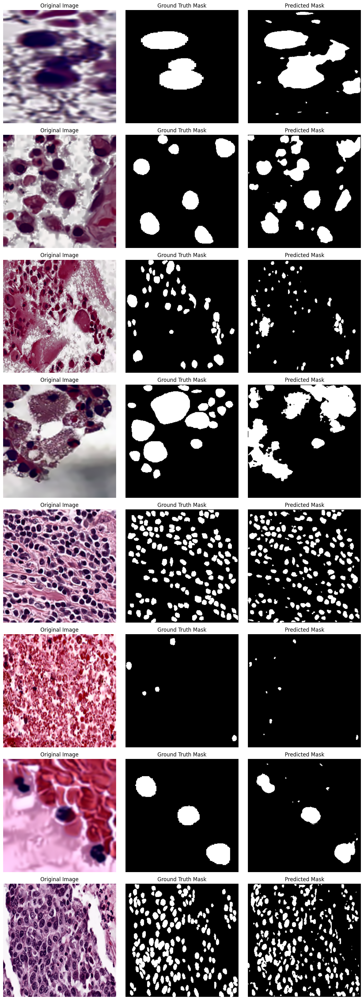

In [ ]:
trained_model.eval()

images = []
ground_truths = []
predictions = []

num_images = 8

with torch.no_grad():
    for i, (inputs, labels) in enumerate(val_loader):
        if i == num_images:
            break

        inputs, labels = inputs.to(device), labels.to(device)

        outputs = trained_model(inputs)
        outputs = torch.sigmoid(outputs)


        preds = (outputs > 0.5).float()


        images.append(inputs.cpu().numpy())
        ground_truths.append(labels.cpu().numpy())
        predictions.append(preds.cpu().numpy())


fig, axes = plt.subplots(num_images, 3, figsize=(12, num_images * 4))
for i in range(num_images):
    ax = axes[i, 0]
    img = images[0][i]
    img = (img-img.min())/(img.max()-img.min())
    ax.imshow(img.transpose(1, 2, 0))
    ax.set_title('Original Image')
    ax.axis('off')

    ax = axes[i, 1]
    ax.imshow(ground_truths[0][i].transpose(1, 2, 0), cmap='gray')
    ax.set_title('Ground Truth Mask')
    ax.axis('off')

    ax = axes[i, 2]
    ax.imshow(predictions[0][i].transpose(1, 2, 0), cmap='gray')
    ax.set_title('Predicted Mask')
    ax.axis('off')

plt.tight_layout()
plt.show()


## Classificazione multiclasse

### Image data

In [ ]:
mask_dir = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_masks'
image_data = []
for patient in os.listdir(mask_dir):
    patient_folder = os.path.join(mask_dir,patient)
    for mask in os.listdir(patient_folder):
        if mask.endswith('.tif'):
            continue
        else:
            mask_folder = os.path.join(patient_folder,mask)
            for class_name in os.listdir(mask_folder):
                class_folder = os.path.join(mask_folder,class_name)
                for file in os.listdir(class_folder):
                    if file.endswith('.png'):
                        image_path = os.path.join(class_folder,file)
                        image_data.append({'path': image_path, 'class': class_name})

print(f"Collected {len(image_data)} image paths.")
if len(image_data) > 0:
    print("First 5 collected image data entries:")
    for i in range(min(5, len(image_data))):
        print(image_data[i])
else:
    print("No image data collected")

Collected 394 image paths.
First 5 collected image data entries:
{'path': 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_masks\\TCGA-55-1594-01Z-00-DX1\\TCGA-55-1594-01Z-00-DX1_001\\Epithelial\\1_mask.png', 'class': 'Epithelial'}
{'path': 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_masks\\TCGA-55-1594-01Z-00-DX1\\TCGA-55-1594-01Z-00-DX1_001\\Lymphocyte\\2_mask.png', 'class': 'Lymphocyte'}
{'path': 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_masks\\TCGA-55-1594-01Z-00-DX1\\TCGA-55-1594-01Z-00-DX1_002\\Lymphocyte\\6_mask.png', 'class': 'Lymphocyte'}
{'path': 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_masks\\TCGA-55-1594-01Z-00-DX1\\TCGA-55-1594-01Z-00-DX1_003\\Lymphocyte\\10_mask.png', 'class': 'Lymphocyte'}
{'path': 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_masks\\TCGA-55-1594-01Z-00-DX1\\TCGA-55-1594-01Z-00-DX1_003\\Macrophage\\12_mask.png', 'class': 'Macrophage'}


### Dataframe

In [ ]:
image_df = pd.DataFrame(image_data) # now i build a dataframe storing all image paths and their corresponding classes

print(f"DataFrame created with {len(image_df)} entries.")
if not image_df.empty:
    print("First 5 rows of the DataFrame:")
    print(image_df.head())
else:
    print("DataFrame is empty.")

DataFrame created with 394 entries.
First 5 rows of the DataFrame:
                                                path       class
0  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...  Epithelial
1  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...  Lymphocyte
2  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...  Lymphocyte
3  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...  Lymphocyte
4  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...  Macrophage


### Controllo casuale

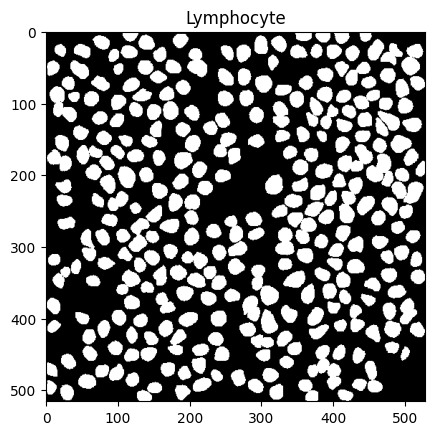

In [ ]:
idx = np.random.randint(0, len(image_df))
img = cv2.imread(image_df.iloc[idx]['path'])

plt.imshow(img)
plt.title(image_df.iloc[idx]['class'])
plt.show()

### Suddivisione del dataframe

In [ ]:
train_df, val_df = train_test_split(
    image_df,
    test_size=0.2,
    stratify=image_df['class'],
    random_state=42 # For reproducibility
)

print(f"Training DataFrame shape: {train_df.shape}")
print(f"Validation DataFrame shape: {val_df.shape}")

print("\nClass distribution in training set:")
print(train_df['class'].value_counts(normalize=True))

print("\nClass distribution in validation set:")
print(val_df['class'].value_counts(normalize=True))

Training DataFrame shape: (315, 2)
Validation DataFrame shape: (79, 2)

Class distribution in training set:
class
Lymphocyte    0.371429
Epithelial    0.244444
Neutrophil    0.238095
Macrophage    0.146032
Name: proportion, dtype: float64

Class distribution in validation set:
class
Lymphocyte    0.367089
Neutrophil    0.240506
Epithelial    0.240506
Macrophage    0.151899
Name: proportion, dtype: float64


### Mapping delle classi

In [ ]:
# map classes to numbers
all_classes = image_df['class'].unique()
class_to_idx = {cls_name: i for i, cls_name in enumerate(sorted(all_classes))} # create a mapping between each class and a number
idx_to_class = {i: cls_name for cls_name, i in class_to_idx.items()}

class GlandsDataset(torch.utils.data.Dataset):
    def __init__(self, dataframe, img_base_dir, transform=None, class_to_idx=None):
        self.dataframe = dataframe
        self.img_base_dir = img_base_dir
        self.transform = transform
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_name = os.path.join(self.img_base_dir, self.dataframe.iloc[idx]['path'])
        #print(f'opening image at path: {self.dataframe.iloc[idx]['path']}')
        image = Image.open(self.dataframe.iloc[idx]['path']).convert('RGB') # PIL image because this is the format that torchvision.transforms require


        label_name = self.dataframe.iloc[idx]['class']

        if self.transform:
            image = self.transform(image)

        # Convert class label to numerical index
        label = self.class_to_idx[label_name]

        return image, label

print("Image transformations defined.")
print("CustomImageDataset class defined.")
print(f"Class to index mapping: {class_to_idx}")

Image transformations defined.
CustomImageDataset class defined.
Class to index mapping: {'Epithelial': 0, 'Lymphocyte': 1, 'Macrophage': 2, 'Neutrophil': 3}


### Definizioni trasformazioni

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()         # Convert images to PyTorch tensor (this automatically rescale images in range (0,1))
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])


train_dataset = GlandsDataset(
    dataframe=train_df,
    img_base_dir='',
    transform=train_transform,
    class_to_idx=class_to_idx
)

val_dataset = GlandsDataset(
    dataframe=val_df,
    img_base_dir='',
    transform=val_transform,
    class_to_idx=class_to_idx
)


batch_size = 16


train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)


val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

# 5. Print the number of samples and batches
print(f"Training dataset size: {len(train_dataset)} samples")
print(f"Validation dataset size: {len(val_dataset)} samples")
print(f"Training DataLoader has {len(train_loader)} batches of size {batch_size}")
print(f"Validation DataLoader has {len(val_loader)} batches of size {batch_size}")

print("DataLoaders created successfully.")

Training dataset size: 315 samples
Validation dataset size: 79 samples
Training DataLoader has 20 batches of size 16
Validation DataLoader has 5 batches of size 16
DataLoaders created successfully.


### Definizione modello

In [ ]:
N_CLASSES = len(class_to_idx)
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights)
num_ftrs = 512
model.fc = nn.Linear(num_ftrs, N_CLASSES)
class_weights = torch.tensor([3.4, 3.0, 3.9, 8.6])
criterion = nn.CrossEntropyLoss(weight = class_weights)
optimizer = torch.optim.SGD(model.parameters(), lr=3e-4)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### Training

In [ ]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()  # Set model to training mode

    running_loss = 0.0
    correct = 0
    total = 0
    all_labels = []
    all_preds = []

    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and update weights
        loss.backward()
        optimizer.step()

        # Update statistics
        running_loss += loss.item() * inputs.size(0)

        # Collect all labels and predictions for F1 score calculation
        _, predicted = torch.max(outputs.data, 1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total

    # compute F1 score for this epoch
    f1 = f1_score(all_labels, all_preds, average='weighted')

    return epoch_loss, f1



def validate_one_epoch(model, dataloader, criterion, device):
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    correct = 0
    total = 0
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)

            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            # NO backward pass and no weights update! We are only monitoring performance
            running_loss += loss.item() * inputs.size(0)

            # Collect all labels and predictions for F1 score calculation
            _, predicted = torch.max(outputs.data, 1)
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(predicted.cpu().numpy())

            total += labels.size(0)

    epoch_loss = running_loss / total

    # compute F1 score for this epoch
    f1 = f1_score(all_labels, all_preds, average='weighted')

    return epoch_loss, f1
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device) # load your model on the device
print(f"Using device: {device}")
optimizer = optim.Adam(model.parameters(), lr=0.001)
num_epochs = 30
print(f"Number of epochs set to: {num_epochs}")

train_losses = []
train_f1s = []
val_losses = []
val_f1s = []

for epoch in range(num_epochs):
    # --- Train phase ---
    epoch_train_loss, epoch_train_f1 = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    train_losses.append(epoch_train_loss)
    train_f1s.append(epoch_train_f1)

    # --- Validation phase ---
    epoch_val_loss, epoch_val_f1 = validate_one_epoch(
        model, val_loader, criterion, device
    )
    val_losses.append(epoch_val_loss)
    val_f1s.append(epoch_val_f1)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_f1:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_f1:.4f}")

print("Training complete.")


Using device: cpu
Number of epochs set to: 30
Epoch 1/30 | Train Loss: 1.4476, Train Acc: 0.4024 | Val Loss: 2.2145, Val Acc: 0.3928
Epoch 2/30 | Train Loss: 1.0706, Train Acc: 0.5263 | Val Loss: 1.1738, Val Acc: 0.4899
Epoch 3/30 | Train Loss: 1.0634, Train Acc: 0.4948 | Val Loss: 1.1479, Val Acc: 0.5256
Epoch 4/30 | Train Loss: 0.9935, Train Acc: 0.5682 | Val Loss: 0.9665, Val Acc: 0.4983
Epoch 5/30 | Train Loss: 0.9898, Train Acc: 0.5948 | Val Loss: 1.2695, Val Acc: 0.5045
Epoch 6/30 | Train Loss: 0.9198, Train Acc: 0.5849 | Val Loss: 1.0282, Val Acc: 0.6149
Epoch 7/30 | Train Loss: 0.8682, Train Acc: 0.6305 | Val Loss: 1.0100, Val Acc: 0.5934
Epoch 8/30 | Train Loss: 0.8485, Train Acc: 0.6424 | Val Loss: 1.2215, Val Acc: 0.4635
Epoch 9/30 | Train Loss: 0.7599, Train Acc: 0.6614 | Val Loss: 1.2074, Val Acc: 0.4941
Epoch 10/30 | Train Loss: 0.6219, Train Acc: 0.7815 | Val Loss: 1.7422, Val Acc: 0.5026
Epoch 11/30 | Train Loss: 0.6899, Train Acc: 0.7270 | Val Loss: 2.1281, Val Acc: 0.

## Risultato

c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedical\MoNuSAC_images_and_annotations\TCGA-J4-A67Q-01Z-00-DX1\TCGA-J4-A67Q-01Z-00-DX1-3_modified.tif
c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedical\MoNuSAC_masks\TCGA-J4-A67Q-01Z-00-DX1\TCGA-J4-A67Q-01Z-00-DX1-3.tif


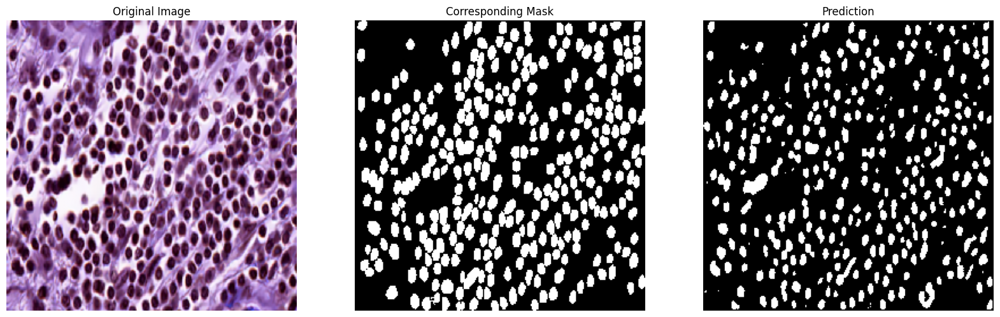

In [ ]:
trained_model.eval()

random_idx = np.random.randint(0, 208)
random_image_path = image_paths[random_idx]
random_mask_path = mask_paths[random_idx]
print(random_image_path)
print(random_mask_path)

image = tiff.imread(random_image_path)
image = image / 255.0
mask = tiff.imread(random_mask_path)
mask = cv2.resize(mask, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_NEAREST)

image = cv2.resize(image, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_NEAREST)
img = torch.from_numpy(image).float()
img = img.permute(2,0,1)
img = img.unsqueeze(0)

with torch.no_grad():

    output = trained_model(img)
    output = torch.sigmoid(output)
    preds = (output > 0.5).float()
    prediction = preds.cpu().numpy()

plt.figure(figsize=(20, 6))

plt.subplot(1,3,1)
plt.imshow(image)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap='gray')
plt.title('Corresponding Mask')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(prediction[0].transpose(1,2,0), cmap='gray')
plt.title('Prediction')
plt.axis('off')

plt.show()
root = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical'
path=os.path.join(root,'PREDICTION.tif')
#Image.fromarray(prediction[0][0]).save(path)



In [ ]:
model.eval()
prediction = preds.float()
prediction = prediction.repeat(1, 3, 1, 1)
with torch.no_grad():
    output = model(prediction)
    prob = torch.sigmoid(output)

prob = prob.squeeze().cpu().numpy()

class_names = ["Epithelial","Lymphocyte","Macrophage","Neutrophil"]
print(prob)
print(class_names)



[0.9818045  0.99128693 0.00224429 0.00110916]
['Epithelial', 'Lymphocyte', 'Macrophage', 'Neutrophil']


# Segmentazione multiclasse

## Operazioni preliminari

### Normalization, equalization, Gaussian filter, mean filter

In [ ]:
#Creazione di immagini modificate
images_base_path = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_images_and_annotations'
for patient in os.listdir(images_base_path):
    patient_folder = os.path.join(images_base_path,patient)
    for image in os.listdir(patient_folder):
        if image.endswith('.tif'):
            image_path = os.path.join(patient_folder,image)
            img = cv2.imread(image_path)
            norm_img = cv2.normalize(img, None, alpha = 0, beta = 255, norm_type = cv2.NORM_MINMAX, dtype = cv2.CV_8UC1)
            img_yuv = cv2.cvtColor(norm_img, cv2.COLOR_BGR2YUV)
            img_yuv[:,:,0] = cv2.equalizeHist(img_yuv[:,:,0])
            img_eq = cv2.cvtColor(img_yuv, cv2.COLOR_YUV2BGR)
            img_gauss = cv2.GaussianBlur(img_eq,(3,3),0)
            img_denoised = cv2.fastNlMeansDenoising(img_gauss,None,10,10)
            eq_img_path = os.path.join(patient_folder,os.path.splitext(image)[0]+'_modified.tif')
            cv2.imwrite(eq_img_path, img_denoised)

### Overlay multiclasse

In [ ]:
masks_base_folder = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\MoNuSAC_masks'
images_base_folder = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\MoNuSAC_images_and_annotations'

for patient in os.listdir(images_base_folder):
    masks_folder = os.path.join(masks_base_folder,patient)
    images_folder = os.path.join(images_base_folder,patient)
    for image_file in os.listdir(images_folder):
        if image_file.endswith('modified.tif'):
            continue
        if image_file.endswith('.tif'):
            msk_folder = os.path.join(masks_folder,os.path.splitext(image_file)[0])
            img = tiff.imread(os.path.join(images_folder,image_file))
            H = img.shape[0]
            W = img.shape[1]
            overlay = np.zeros((H,W), dtype=np.uint8)
            for layer in os.listdir(msk_folder):
                msk_layer = os.path.join(msk_folder,layer)
                for msk in os.listdir(msk_layer):
                    if msk.endswith('.tif'):
                        msk_file = tiff.imread(os.path.join(msk_layer,msk))
                        n_msk_file = (msk_file > 0).astype(np.uint8)
                        if layer.endswith('Epithelial'):
                            overlay[(n_msk_file == 1)] = 1
                        if layer.endswith('Lymphocyte'):
                            overlay[(n_msk_file == 1)] = 2
                        if layer.endswith('Macrophage'):
                            overlay[(n_msk_file == 1)] = 3
                        if layer.endswith('Neutrophil'):
                            overlay[(n_msk_file == 1)] = 4
            Image.fromarray(overlay).save(msk_folder+'.tif')
            

## Segmentazione

### Creazione dataframe

In [29]:
images_base_path = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_images_and_annotations'
masks_base_path = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_masks'

image_paths = []
mask_paths = []
classes=[]

for name in os.listdir(images_base_path):
    image_folder = os.path.join(images_base_path, name)
    mask_folder = os.path.join(masks_base_path, name)
    if os.path.isdir(image_folder) and os.path.isdir(mask_folder):
        for image_file in os.listdir(image_folder):
            if image_file.endswith('modified.tif'):
                img_path = os.path.join(image_folder, image_file)
                tmp = image_file.replace("_modified.tif", ".tif")
                msk_path = os.path.join(mask_folder,tmp)
                if os.path.exists(img_path) & os.path.exists(msk_path):
                    image_paths.append(img_path)
                    mask_paths.append(msk_path)
                    classes.append('.')
                else:
                    print(f"Mask not found for image: {img_path}")

# Create the pandas DataFrame
df = pd.DataFrame({"image_path": image_paths, "mask_path": mask_paths, "class": classes})

print(f"DataFrame created with {len(df)} entries.")
print(df.head())

DataFrame created with 209 entries.
                                          image_path  \
0  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...   
1  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...   
2  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...   
3  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...   
4  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...   

                                           mask_path class  
0  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...     .  
1  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...     .  
2  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...     .  
3  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...     .  
4  c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedic...     .  


### Controllo casuale

c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedical\MoNuSAC_images_and_annotations\TCGA-J4-A67Q-01Z-00-DX1\TCGA-J4-A67Q-01Z-00-DX1-1_modified.tif
c:\Users\nicoz\OneDrive\Desktop\Corsi\Biomedical\MoNuSAC_masks\TCGA-J4-A67Q-01Z-00-DX1\TCGA-J4-A67Q-01Z-00-DX1-1.tif


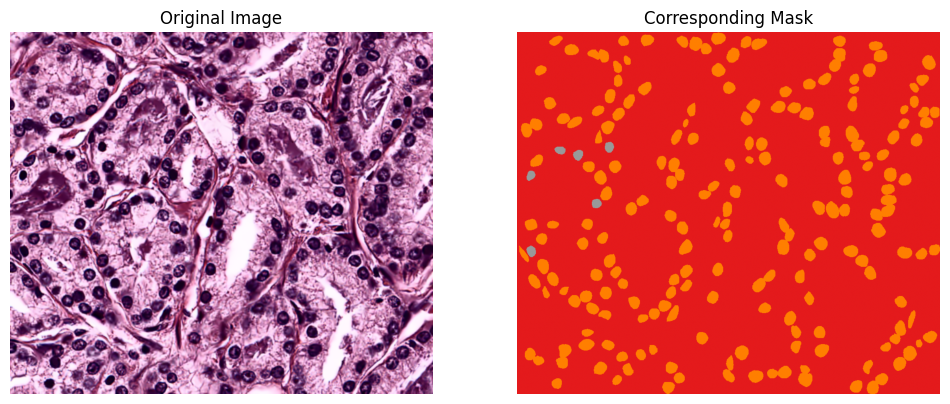

In [30]:
random_idx = np.random.randint(0, len(df))
random_image_path = df.loc[random_idx, 'image_path']
random_mask_path = df.loc[random_idx, 'mask_path']
print(random_image_path)
print(random_mask_path)

image = tiff.imread(random_image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
mask = tiff.imread(random_mask_path)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap='Set1') #per visualizzazione
plt.title('Corresponding Mask')
plt.axis('off')

plt.show()

### Trasformazioni al dataframe

In [31]:
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 256

train_transforms = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=45, interpolation=cv2.INTER_LINEAR, border_mode=cv2.BORDER_REFLECT_101, p=0.5),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    ToTensorV2(),
])


In [32]:
class GlandsDataset(torch.utils.data.Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'image_path']
        mask_path = self.df.loc[idx, 'mask_path']

        image = tiff.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = image.astype(np.float32) / 255.0 # normalize

        mask = tiff.imread(mask_path)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        if len(mask.shape) == 2:
            mask = mask.unsqueeze(0)

        return image, mask.float() # for loss function



### Suddivisione del dataframe

In [33]:
train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['class'],
    random_state=42 # For reproducibility
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Training DataFrame shape: {train_df.shape}")
print(f"Validation DataFrame shape: {val_df.shape}")

Training DataFrame shape: (167, 3)
Validation DataFrame shape: (42, 3)


In [34]:
BATCH_SIZE = 8

train_dataset = GlandsDataset(train_df, transform=train_transforms)
val_dataset = GlandsDataset(val_df, transform=val_transforms)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Training dataloader batches: {len(train_loader)}")
print(f"Validation dataloader batches: {len(val_loader)}")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Training dataset size: 167
Validation dataset size: 42
Training dataloader batches: 21
Validation dataloader batches: 6
Using device: cpu


### Controllo casuale

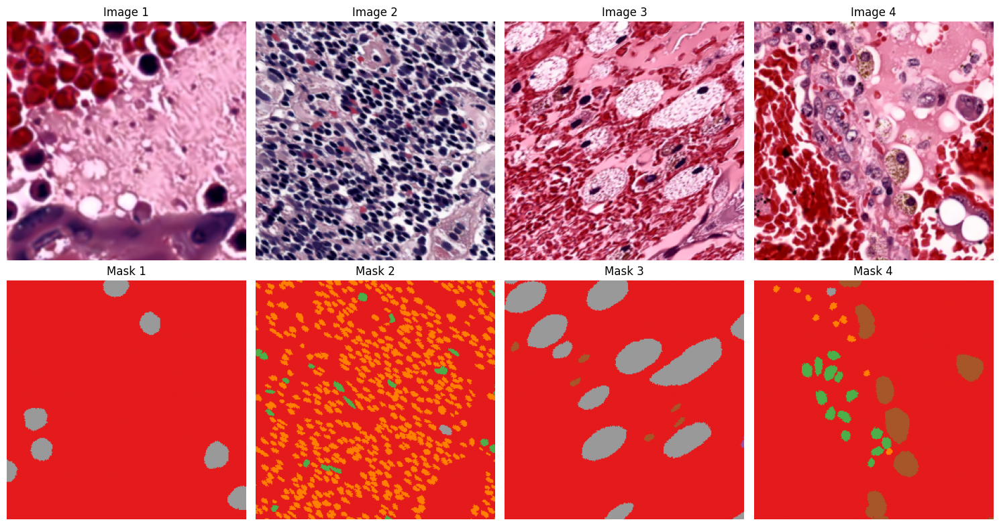

In [35]:
images, masks = next(iter(train_loader))
images = images.cpu()
maps = masks.cpu()
display_images = images

num_samples_to_show = min(4, BATCH_SIZE)

plt.figure(figsize=(15, 8))
for i in range(num_samples_to_show):
    # Original Image
    plt.subplot(2, num_samples_to_show, i + 1)
    img = display_images[i]
    img = (img - img.min())/(img.max()-img.min())
    plt.imshow(display_images[i].permute(1, 2, 0))
    plt.title(f'Image {i+1}')
    plt.axis('off')

    # Corresponding Mask
    plt.subplot(2, num_samples_to_show, i + 1 + num_samples_to_show)
    plt.imshow(maps[i].squeeze(0), cmap='Set1') # Squeeze channel dimension for grayscale mask
    plt.title(f'Mask {i+1}')
    plt.axis('off')

plt.tight_layout()
plt.show()

### Implementazione della rete neurale

In [36]:
def conv_bn_leru(in_channels, out_channels, kernel_size=3, stride=1, padding=1):
  """
  Implements the sequence of: convolution, batch normalization, and relu activation function (x2)
  """

  return nn.Sequential(
          nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding),
          nn.BatchNorm2d(out_channels),
          nn.ReLU(inplace=True),
          nn.Conv2d(out_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding),
          nn.BatchNorm2d(out_channels),
          nn.ReLU(inplace=True),
  )


def down_pooling():
  """
  Max pooling operation, with a kernel size of 2x2 and a stride of 2
  """
  return nn.MaxPool2d(2, stride = 2)


def up_pooling(in_channels, out_channels, kernel_size=2, stride=2):
    """
    Perform the up scaling operation
    """
    return nn.Sequential(
        nn.ConvTranspose2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )


class UNet(nn.Module):
    """U-Net architecture"""

    def __init__(self, input_channels, nclasses):
        super().__init__()

        self.nclasses = nclasses
        # Encoding layers
        self.conv1 = conv_bn_leru(input_channels,16)
        self.conv2 = conv_bn_leru(16, 32)
        self.conv3 = conv_bn_leru(32, 64)
        self.conv4 = conv_bn_leru(64, 128)
        self.conv5 = conv_bn_leru(128, 256)
        self.down_pooling = down_pooling()

        # Decoding layers
        self.up_pool6 = up_pooling(256, 128)
        self.conv6 = conv_bn_leru(256, 128)
        self.up_pool7 = up_pooling(128, 64)
        self.conv7 = conv_bn_leru(128, 64)
        self.up_pool8 = up_pooling(64, 32)
        self.conv8 = conv_bn_leru(64, 32)
        self.up_pool9 = up_pooling(32, 16)
        self.conv9 = conv_bn_leru(32, 16)

        self.conv10 = nn.Conv2d(16, self.nclasses, 1)


    def forward(self, x):
        # --- Encoder ---
        x1 = self.conv1(x)
        p1 = self.down_pooling(x1)
        x2 = self.conv2(p1)
        p2 = self.down_pooling(x2)
        x3 = self.conv3(p2)
        p3 = self.down_pooling(x3)
        x4 = self.conv4(p3)
        p4 = self.down_pooling(x4)
        x5 = self.conv5(p4)

        # --- Decoder ---
        p6 = self.up_pool6(x5)
        x6 = torch.cat([p6, x4], dim=1)
        x6 = self.conv6(x6)

        p7 = self.up_pool7(x6)
        x7 = torch.cat([p7, x3], dim=1)
        x7 = self.conv7(x7)

        p8 = self.up_pool8(x7)
        x8 = torch.cat([p8, x2], dim=1)
        x8 = self.conv8(x8)

        p9 = self.up_pool9(x8)
        x9 = torch.cat([p9, x1], dim=1)
        x9 = self.conv9(x9)

        output = self.conv10(x9)

        return output


In [37]:
print("Checking batch shapes:")

# Get a batch from the train dataloader
for images, masks in train_loader:
    print(f"Train Dataloader - Images shape: {images.shape}")
    print(f"Train Dataloader - Masks shape: {masks.shape}")
    break

# Get a batch from the val dataloader
for images, masks in val_loader:
    print(f"Validation Dataloader - Images shape: {images.shape}")
    print(f"Validation Dataloader - Masks shape: {masks.shape}")
    break

Checking batch shapes:
Train Dataloader - Images shape: torch.Size([8, 3, 256, 256])
Train Dataloader - Masks shape: torch.Size([8, 1, 256, 256])
Validation Dataloader - Images shape: torch.Size([8, 3, 256, 256])
Validation Dataloader - Masks shape: torch.Size([8, 1, 256, 256])


In [38]:
def dice_score(pred, target):
    smooth = 1e-6
    intersection = torch.sum(pred * target)
    return (2. * intersection + smooth) / (torch.sum(pred) + torch.sum(target) + smooth)

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0

    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        labels_mod = np.squeeze(labels).long()
        outputs = model(inputs)

        # loss computation
        loss = criterion(outputs,labels_mod)

        # Backward pass and update weights
        loss.backward()
        optimizer.step()

        # Update statistics
        running_loss += loss.item() * inputs.size(0)
    epoch_loss = running_loss / len(dataloader.dataset)

    return epoch_loss

def validate_one_epoch(model, dataloader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_labels_flat = []
    all_preds_flat = []
    dice_total = 0.0
    num_samples = 0

    # disable gradients
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)

            # Forward pass
            outputs = model(inputs)
            labels_mod = np.squeeze(labels).long()

            # loss computation
            loss = criterion(outputs,labels_mod)

            # Update statistics
            running_loss += loss.item() * inputs.size(0)

            #Argmax
            preds = torch.argmax(outputs,dim=1)


            for i in range(inputs.size(0)):
                dice_total += dice_score(preds[i],labels_mod[i])

            all_labels_flat.extend(labels_mod.cpu().numpy().ravel())
            all_preds_flat.extend(preds.cpu().numpy().ravel())

            num_samples += inputs.size(0)

    epoch_loss = running_loss / num_samples
    epoch_dice = dice_total / num_samples

    all_labels_flat = np.array(all_labels_flat)
    all_preds_flat = np.array(all_preds_flat)
    f1 = f1_score(all_labels_flat > 0, all_preds_flat > 0, average='weighted')

    return epoch_loss, f1, epoch_dice

def train_loop(model, train_loader, val_loader, criterion, optimizer, num_epochs, device):
    best_f1 = 0.0  # initialize best f1 score
    best_model_wts = model.state_dict()  # Save the best model's weights

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')

        # --- Train ---
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
        print(f'Training Loss: {train_loss:.4f}')

        # --- Validate ---
        val_loss, val_f1, val_dice = validate_one_epoch(model, val_loader, criterion, device)
        print(f'Validation Loss: {val_loss:.4f}, F1: {val_f1:.4f}, Dice: {val_dice:.4f}')

        # Save the model with the best f1 score
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_model_wts = model.state_dict()
            print('Best model updated!')

    # Load the best model weights
    model.load_state_dict(best_model_wts)
    print(f'Best model F1 score: {best_f1:.4f}')

    return model

In [39]:
model = UNet(input_channels=3, nclasses=5).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = torch.nn.CrossEntropyLoss()
num_epochs = 35

print(model)


UNet(
  (conv1): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (conv2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (conv3): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_runnin

In [40]:
print("Checking model input and output dimensions:")
images, masks = next(iter(train_loader))
images = images.to(device)
print(f"Input image batch shape: {images.shape}")
model_output = model(images)
print(f"Model output batch shape: {model_output.shape}")

Checking model input and output dimensions:
Input image batch shape: torch.Size([8, 3, 256, 256])
Model output batch shape: torch.Size([8, 5, 256, 256])


### Training

In [41]:
trained_model = train_loop(model, train_loader, val_loader, criterion, optimizer, num_epochs, device)

Epoch 1/35
Training Loss: 1.5877
Validation Loss: 1.5177, F1: 0.7327, Dice: 1.1090
Best model updated!
Epoch 2/35
Training Loss: 1.3245
Validation Loss: 1.2517, F1: 0.7972, Dice: 1.1036
Best model updated!
Epoch 3/35
Training Loss: 1.1675
Validation Loss: 1.0803, F1: 0.8113, Dice: 1.0376
Best model updated!
Epoch 4/35
Training Loss: 1.0290
Validation Loss: 0.9644, F1: 0.8741, Dice: 1.2814
Best model updated!
Epoch 5/35
Training Loss: 0.9051
Validation Loss: 0.8355, F1: 0.8728, Dice: 1.2961
Epoch 6/35
Training Loss: 0.7980
Validation Loss: 0.7803, F1: 0.8616, Dice: 1.1536
Epoch 7/35
Training Loss: 0.7084
Validation Loss: 0.6709, F1: 0.8653, Dice: 1.2252
Epoch 8/35
Training Loss: 0.6400
Validation Loss: 0.6084, F1: 0.8649, Dice: 1.1502
Epoch 9/35
Training Loss: 0.6129
Validation Loss: 0.6273, F1: 0.8580, Dice: 1.1600
Epoch 10/35
Training Loss: 0.5824
Validation Loss: 0.5493, F1: 0.8506, Dice: 0.9779
Epoch 11/35
Training Loss: 0.5583
Validation Loss: 0.4911, F1: 0.8448, Dice: 0.9828
Epoch

## Risultato

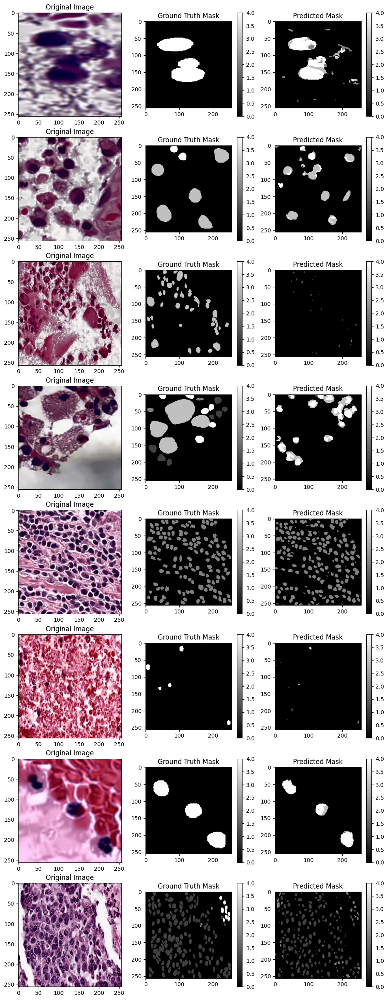

In [42]:
trained_model.eval()

all_images = []
all_ground_truths = []
all_preds = []

num_images = 8

with torch.no_grad():
    for i, (inputs, labels) in enumerate(val_loader):
        if i == num_images:
            break

        inputs, labels = inputs.to(device), labels.to(device)

        outputs = trained_model(inputs)
        preds = torch.argmax(outputs,dim=1)



        for b in range(inputs.size(0)):
            all_images.append(inputs[b].cpu().numpy())
            all_ground_truths.append(labels[b].cpu().numpy())
            all_preds.append(preds[b].cpu().numpy())
plt.subplots(num_images,3,figsize=(12,num_images*4))
for i in range(num_images):
    plt.subplot(num_images,3,3*i+1)
    plt.imshow(all_images[i].transpose(1, 2, 0))
    plt.title('Original Image')

    plt.subplot(num_images,3,3*i+2)
    plt.imshow(all_ground_truths[i].transpose(1,2,0), cmap='gray', vmin=0, vmax=4)
    plt.colorbar()
    plt.title('Ground Truth Mask')

    plt.subplot(num_images,3,3*i+3)
    plt.imshow(all_preds[i], cmap='gray', vmin=0, vmax=4)
    plt.colorbar()
    plt.title('Predicted Mask')

plt.show()


# Tentativi

## Conteggio pixel per pesi

### per classificazione multiclasse

In [ ]:
root = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_masks'
class_0 = 0
class_1 = 0
class_2 = 0
class_3 = 0
class_4 = 0
for patient in os.listdir(root):
    patient_folder = os.path.join(root, patient)
    for image in os.listdir(patient_folder):
        folder_path = os.path.join(patient_folder,image)
        if os.path.isdir(folder_path):
            for masks in os.listdir(folder_path):
                masks_folder = os.path.join(folder_path,masks)
                for file in os.listdir(masks_folder):
                    if file.endswith('.tif'):
                        img_file = tiff.imread(os.path.join(masks_folder,file))
                        img_file = cv2.resize(img_file,(256,256),interpolation=cv2.INTER_NEAREST)
                        img = np.asarray(img_file)
                        if masks == 'Epithelial':
                            for i in range(256):
                                for j in range(256):
                                    if img[i][j]==0:
                                        class_0 += 1
                                    if img[i][j]==255:
                                        class_1 += 1
                        if masks == 'Lymphocyte':
                            for i in range(256):
                                for j in range(256):
                                    if img[i][j]==0:
                                        class_0 += 1
                                    if img[i][j]==255:
                                        class_2 += 1
                        if masks == 'Macrophage':
                            for i in range(256):
                                for j in range(256):
                                    if img[i][j]==0:
                                        class_0 += 1
                                    if img[i][j]==255:
                                        class_3 += 1
                        if masks == 'Neutrophil':
                            for i in range(256):
                                for j in range(256):
                                    if img[i][j]==0:
                                        class_0 += 1
                                    if img[i][j]==255:
                                        class_4 += 1

sum=class_1+class_2+class_3+class_4
print(f'0: {class_0}, 1: {class_1}, 2: {class_2}, 3: {class_3}, 4: {class_4}, sum={sum}')
print(f'1: {sum/class_1}, 2: {sum/class_2}, 3: {sum/class_3}, 4: {sum/class_4}')

### per segmentazione multiclasse

In [ ]:
root = 'c:\\Users\\nicoz\\OneDrive\\Desktop\\Corsi\\Biomedical\\MoNuSAC_masks'
class_0 = 0
class_1 = 0
class_2 = 0
class_3 = 0
class_4 = 0
for patient in os.listdir(root):
    patient_folder = os.path.join(root, patient)
    for image in os.listdir(patient_folder):
        if image.endswith('.tif'):
            img_file = tiff.imread(os.path.join(patient_folder,image))
            img_file = cv2.resize(img_file,(256,256),interpolation=cv2.INTER_NEAREST)
            img = np.asarray(img_file)
            for i in range(256):
                    for j in range(256):
                        if img[i][j]==0:
                                    class_0 += 1
                        if img[i][j]==1:
                                    class_1 += 1
                        if img[i][j]==2:
                                    class_2 += 1
                        if img[i][j]==3:
                                    class_3 += 1
                        if img[i][j]==4:
                                    class_4 += 1
print(f'0: {class_0}, 1: {class_1}, 2: {class_2}, 3: {class_3}, 4: {class_4}')

